## Model 3: the $^{167}$Er$^{3+}$:Y$_2$SiO$_5$ (site 2) hyperfine Hamiltonian and its validation

Model 3 is Er$^{3+}$ at crystallographic site 2 of Y$_2$SiO$_5$ (C$_1$ point symmetry) including the hyperfine structure of $^{167}$Er ($I=7/2$), in a magnetic field $\vec B$. Its source is N. L. Jobbitt, J.-P. R. Wells, M. F. Reid, S. P. Horvath, P. Goldner and A. Ferrier, Phys. Rev. B **104**, 155121 (2021), [arXiv:2206.09080](https://arxiv.org/abs/2206.09080):
$$H(\vec B) = H_{\rm FI} + \sum_{k,q} B^k_q C^{(k)}_q + a_l\, H_{\rm HF} + a_Q\, H_{\rm Q} + \mu_B \vec B\cdot(\vec L + g_s \vec S) - g_n\mu_N \vec B\cdot\vec I .$$
All 27 crystal-field parameters are independent in C$_1$ symmetry (complex $B^k_q$ for $q>0$). As in the paper, the hyperfine Hamiltonian is evaluated in PyCF's `erhfs` basis: the intermediate-coupled $^4I_{15/2}$ and $^4I_{13/2}$ multiplets times the 8 nuclear states, $(16+14)\times 8 = 240$ states, embedded in 256 dimensions (8 qubits). Axes are $x, y, z$ = D1, D2, b.

The energy scales span six orders of magnitude: 6 500 cm$^{-1}$ between the two multiplets, 27–140 cm$^{-1}$ between crystal-field levels, about 0.2 cm$^{-1}$ of hyperfine structure inside each level, and avoided crossings of a few MHz ($10^{-4}$ cm$^{-1}$). The zero-first-order-Zeeman (ZEFOZ) points of the hyperfine transitions of the lowest level Z1 are the quantity of physical interest: at those fields a qubit transition is insensitive to magnetic noise. K. Matsuura, S. Yasui, R. Kaji, H. Sasakura, T. Tawara and S. Adachi, Phys. Rev. B **113**, 085421 (2026), [arXiv:2412.10126](https://arxiv.org/abs/2412.10126), mapped them with an effective spin Hamiltonian.

This notebook validates the Hamiltonian before any DBQA run:
1. transcription of the parameters (crystal-field strengths of Table III);
2. the full $4f^{11}$ configuration (PyCF `f11cf`) against the levels and g values of Table II;
3. the 240-state hyperfine Hamiltonian against the 7 T hyperfine splittings of Table VI;
4. the ZEFOZ points: Matsuura et al.'s Table V from their spin Hamiltonian, and the ZEFOZ points of the crystal-field model, which fix the field sweep used for DBQA in `Example_9`.

In [1]:
import os

# one BLAS thread: these matrices are too small to profit from more, and forked workers must not inherit spinning BLAS threads
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import csv
import itertools
import logging
import multiprocessing as mp
import pickle
import time
from concurrent.futures import ProcessPoolExecutor

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

from qibo import set_backend
from qibo.config import log

from pycf.import_sljm import ImportSLJM

from qibo_dbqa.utils_crystal_field import *

# PyCF source tree with the bundled matrix-element bases (examples/*/matel)
os.environ.setdefault("PYCF_ROOT", os.path.abspath("../../../pycf"))

set_backend("numpy")
log.setLevel(logging.ERROR)
os.makedirs("pdfs_figures", exist_ok=True)
os.makedirs("simulation_results", exist_ok=True)


def rms(x):
    return np.sqrt(np.mean(np.asarray(x) ** 2))

[Qibo 0.2.14|INFO|2026-10-17 07:22:16]: Using numpy backend on /CPU:0


#### Parameters

Table III of Jobbitt et al. gives $E_{\rm avg}$, $F^2, F^4, F^6$, $\zeta$, the 27 crystal-field parameters and the hyperfine constants $a_l$, $a_Q$ for site 2 ("This study"). The other free-ion parameters are fixed to Carnall's Er$^{3+}$:LaF$_3$ values (their Table IV). $M^2, M^4, P^4, P^6$ follow from $M^0$ and $P^2$ through the ratios of PyCF's Er:YSO example (0.56, 0.31, 0.50, 0.10). Inside the `erhfs` basis these only shift the two multiplets.

The crystal-field strengths $S_k = [(|B^k_0|^2 + 2\sum_{q>0}|B^k_q|^2)/(2k+1)]^{1/2}$ are listed in Table III and check the transcription of all 27 parameters.

In [2]:
coeff = er_yso_pycf_coeff()
for name in ["EAVG", "F2", "F4", "F6", "ZETA"] + [f"C{k}{q}" for k in (2, 4, 6) for q in range(k + 1)]:
    print(f"{name:5s} {coeff[name]}")
print("hyperfine:", ER_YSO_SITE2_HYPERFINE_JOBBITT2021)
strengths = [crystal_field_strength(coeff, k) for k in (2, 4, 6)]
print(f"\nS2, S4, S6 = {np.round(strengths, 1)} cm^-1 (Table III: 363.1, 653.3, 151.5)")

EAVG  35507.5
F2    96121.9
F4    67722.4
F6    53241.2
ZETA  2362.3
C20   389.0
C21   (-325.7-95.8j)
C22   (-368.5+53.7j)
C40   17.2
C41   (-378.7-519.5j)
C42   (-72-146j)
C43   (-890.8+570.4j)
C44   (-198.7-567.9j)
C60   73.4
C61   (-37.5+49.9j)
C62   (135.5+60.6j)
C63   (-166.7+131.8j)
C64   (227.2+47.6j)
C65   (119.5+64.3j)
C66   (37.6-41.3j)
hyperfine: {'HYP': 0.005389, 'EQHYP': 0.024}

S2, S4, S6 = [363.1 653.3 151.5] cm^-1 (Table III: 363.1, 653.3, 151.5)


#### The full $4f^{11}$ configuration against Table II

`data/Er_YSO_site2_Jobbitt2021_Table2.csv` transcribes Table II (59 levels up to $^4G_{11/2}$, 57 with an experimental energy, and the g values along D1, D2 and b). The PyCF levels are compared with the paper's calculated levels, multiplet by multiplet.

In [3]:
with open("data/Er_YSO_site2_Jobbitt2021_Table2.csv") as file:
    table = list(csv.DictReader(line for line in file if not line.startswith("#")))
multiplets = [row["multiplet"] for row in table]
names = list(dict.fromkeys(multiplets))
e_calc_paper = np.array([float(row["E_calc"]) for row in table])
measured = np.array([row["E_exp"] != "" for row in table])
e_exp = np.array([float(row["E_exp"]) for row in table if row["E_exp"]])
print(f"{len(table)} levels in Table II, {measured.sum()} measured")
print(f"paper fit: calc - exp rms = {rms(e_calc_paper[measured] - e_exp):.2f} cm^-1, max = {np.max(np.abs(e_calc_paper[measured] - e_exp)):.0f} cm^-1")

f11cf = ImportSLJM(pycf_matel_path("f11cf", "eryso"))


def f11cf_levels(coeff):
    return np.linalg.eigvalsh(pycf_dense_matrix([getattr(f11cf, name) for name in coeff], coeff))[::2][: len(table)]


energies_f11, vectors_f11 = np.linalg.eigh(pycf_dense_matrix([getattr(f11cf, name) for name in coeff], coeff))
levels = energies_f11[::2][: len(table)]
residual = levels - e_calc_paper
print(f"\nPyCF with the paper's parameters: PyCF - paper calc rms = {rms(residual):.1f} cm^-1, max = {np.max(np.abs(residual)):.1f} cm^-1; "
      f"PyCF - exp rms = {rms(levels[measured] - e_exp):.1f} cm^-1")
print(f"\n{'multiplet':10s} {'mean shift':>11s} {'spread':>8s}   (PyCF - paper calc, cm^-1)")
for name in names:
    inside = residual[[m == name for m in multiplets]]
    print(f"{name:10s} {np.mean(inside):11.1f} {np.ptp(inside):8.1f}")
inside_rms = rms(np.concatenate([residual[[m == n for m in multiplets]] - np.mean(residual[[m == n for m in multiplets]]) for n in names]))
print(f"\nafter removing one shift per multiplet: rms {inside_rms:.2f} cm^-1")

59 levels in Table II, 57 measured
paper fit: calc - exp rms = 12.74 cm^-1, max = 26 cm^-1



PyCF with the paper's parameters: PyCF - paper calc rms = 21.9 cm^-1, max = 37.7 cm^-1; PyCF - exp rms = 21.8 cm^-1

multiplet   mean shift   spread   (PyCF - paper calc, cm^-1)
4I15/2            33.0      1.6
4I13/2             8.1      1.7
4I11/2            25.7      1.1
4I9/2             36.7      1.5
4F9/2              3.9      2.1
4S3/2             -4.4      1.3
2H11/2           -25.4      1.0
4F7/2             -3.8      2.7
4F5/2             -4.3      1.9
4F3/2             -4.6      0.2
2H9/2            -24.8      1.6
4G11/2           -14.5      1.0

after removing one shift per multiplet: rms 0.59 cm^-1


**Result.** The crystal-field splittings inside every multiplet agree with the paper's calculated levels to about 1 cm$^{-1}$ rms. The multiplets themselves are shifted, by between $-26$ and $+37$ cm$^{-1}$. The next cell rules out the obvious explanations:
- a refit of $E_{\rm avg}$, $F^k$ and $\zeta$ (or of any single further free-ion parameter) to the paper's calculated levels;
- Carnall's own ratios for $M^k$ and $P^k$ (0.56, 0.38, 0.75, 0.50) instead of PyCF's;
- the truncation of the crystal-field matrix to free-ion states below 40 000 cm$^{-1}$ mentioned in the paper;
- a transcription error specific to site 2: the site-1 parameters of the same table give the same multiplet pattern against Table I.

In [4]:
free = ["EAVG", "F2", "F4", "F6", "ZETA"]


def refit(free, extra=()):
    names_fit = list(free) + list(extra)
    x0 = np.array([coeff[n] for n in names_fit])

    def residuals(x):
        trial = dict(ER_YSO_SITE2_JOBBITT2021, **dict(zip(names_fit, x)))
        return f11cf_levels(er_yso_pycf_coeff(trial)) - e_calc_paper

    solution = least_squares(residuals, x0, x_scale=np.maximum(np.abs(x0) * 1e-2, 1.0), diff_step=1e-6, max_nfev=200)
    return rms(solution.fun), dict(zip(names_fit, solution.x))


start = time.time()
value, fit = refit(free)
print(f"refit E_avg, F^k, zeta to the paper's calculated levels: rms {value:.2f} cm^-1 ({', '.join(f'{n} {coeff[n]:.1f} -> {fit[n]:.1f}' for n in free)})")
for extra in ["ALPHA", "BETA", "GAMMA", "M0", "P2"]:
    value, fit = refit(free, [extra])
    print(f"   + {extra:5s}: rms {value:.2f} cm^-1 ({extra} {coeff[extra]:.2f} -> {fit[extra]:.2f})")
carnall = dict(coeff, M4=0.38 * coeff["M0"], P4=0.75 * coeff["P2"], P6=0.50 * coeff["P2"])
print(f"Carnall's M and P ratios: PyCF - paper calc rms {rms(f11cf_levels(carnall) - e_calc_paper):.1f} cm^-1")

# crystal field restricted to the free-ion states below 40 000 cm^-1
matrix_fi = pycf_dense_matrix([getattr(f11cf, n) for n in coeff if not n.startswith("C")], {n: v for n, v in coeff.items() if not n.startswith("C")})
matrix_cf = pycf_dense_matrix([getattr(f11cf, n) for n in coeff if n.startswith("C")], {n: v for n, v in coeff.items() if n.startswith("C")})
e_fi, v_fi = np.linalg.eigh(matrix_fi)
v_low = v_fi[:, e_fi < 40000]
truncated = np.linalg.eigvalsh(v_low.conj().T @ (matrix_fi + matrix_cf) @ v_low)[::2][: len(table)]
print(f"crystal field truncated to the {v_low.shape[1]} free-ion states below 40 000 cm^-1: rms {rms(truncated - e_calc_paper):.1f} cm^-1")

# site 1 (Table III and Table I of the same paper)
site1 = dict(ER_YSO_SITE2_JOBBITT2021, EAVG=35491.3, F2=95805.7, F4=67869.7, F6=53148.2, ZETA=2360.5,
             C20=-479.6, C21=471.4 + 143.8j, C22=125.5 - 2.0j, C40=-640.6, C41=288.8 + 924.1j, C42=-273.9 + 320.9j,
             C43=-873.7 - 367.8j, C44=-600.8 + 1210.5j, C60=145.7, C61=-105.9 - 329.0j, C62=-119.9 + 164.1j,
             C63=1.1 + 133.3j, C64=-84.6 + 36.9j, C65=75.5 + 6.9j, C66=-48.5 + 118.0j)
e_calc_site1 = np.array([-10, 39, 72, 111, 179, 416, 474, 509, 6518, 6564, 6599, 6637, 6805, 6866, 6887, 10189, 10231, 10258,
                         10345, 10386, 10396, 12337, 12430, 12532, 12606, 12656, 15185, 15236, 15360, 15402, 15493, 18272,
                         18359, 19115, 19152, 19177, 19242, 19277, 19302, 20424, 20468, 20557, 20633, 22099, 22130, 22217,
                         22470, 22601, 24403, 24515, 24594, 24639, 24686, 26207, 26223, 26322, 26469, 26514, 26577], float)
residual_site1 = f11cf_levels(er_yso_pycf_coeff(site1)) - e_calc_site1
print(f"\n{'multiplet':10s} {'site 2':>8s} {'site 1':>8s}   mean PyCF - paper calc (cm^-1)")
for name in names:
    mask = [m == name for m in multiplets]
    print(f"{name:10s} {np.mean(residual[mask]):8.1f} {np.mean(residual_site1[mask]):8.1f}")
print(f"({time.time() - start:.0f} s)")

refit E_avg, F^k, zeta to the paper's calculated levels: rms 12.05 cm^-1 (EAVG 35507.5 -> 35563.1, F2 96121.9 -> 96466.9, F4 67722.4 -> 67799.2, F6 53241.2 -> 53616.0, ZETA 2362.3 -> 2366.8)


   + ALPHA: rms 11.82 cm^-1 (ALPHA 17.79 -> 18.28)


   + BETA : rms 11.82 cm^-1 (BETA -582.10 -> -569.48)


   + GAMMA: rms 11.96 cm^-1 (GAMMA 1800.00 -> 2911.24)


   + M0   : rms 9.29 cm^-1 (M0 3.86 -> 3.28)


   + P2   : rms 11.12 cm^-1 (P2 594.00 -> 715.89)
Carnall's M and P ratios: PyCF - paper calc rms 21.4 cm^-1
crystal field truncated to the 216 free-ion states below 40 000 cm^-1: rms 21.1 cm^-1

multiplet    site 2   site 1   mean PyCF - paper calc (cm^-1)
4I15/2         33.0     32.0
4I13/2          8.1      7.0
4I11/2         25.7     24.0
4I9/2          36.7     34.3
4F9/2           3.9      1.4
4S3/2          -4.4     -7.0
2H11/2        -25.4    -29.2
4F7/2          -3.8     -7.5
4F5/2          -4.3     -7.5
4F3/2          -4.6     -8.4
2H9/2         -24.8    -29.9
4G11/2        -14.5    -21.4
(10 s)


**Conclusion.** Both sites show the same multiplet-dependent offsets, and no physically sensible change of the free-ion parameters removes them. Some convention of the free-ion operators in PyCF's bundled `f11cf` basis therefore differs from the program used to produce Tables I and II; we cannot identify it from the paper. The offsets are rigid shifts of whole multiplets. They do not affect the crystal-field wave functions inside a multiplet, which set the g values and the hyperfine structure. The next cell checks the g values of all 59 levels.

In [5]:
mag = [pycf_dense_matrix([getattr(f11cf, "MAG" + axis)], {"MAG" + axis: 1.0}) for axis in "XYZ"]
g_pycf = np.array([[np.ptp(np.linalg.eigvalsh(vectors_f11[:, 2 * k: 2 * k + 2].conj().T @ m @ vectors_f11[:, 2 * k: 2 * k + 2])) for m in mag] for k in range(len(table))])
columns = [("gD1_calc", "gD1_exp"), ("gD2_calc", "gD2_exp"), ("gb_calc", "gb_exp")]
g_calc = np.array([[float(row[c]) for c, _ in columns] for row in table])
print(f"{'state':5s} {'PyCF g (D1, D2, b)':>22s} {'paper calc':>20s} {'experiment':>22s}")
for k in (0, 8):
    exp = [table[k][e] or "-" for _, e in columns]
    print(f"{table[k]['state']:5s} {np.array2string(g_pycf[k], precision=2):>22s} {np.array2string(g_calc[k], precision=2):>20s} {', '.join(exp):>22s}")
difference = g_pycf - g_calc
print(f"\nall 59 levels, 3 axes: PyCF - paper calc rms {rms(difference):.2f}, max {np.max(np.abs(difference)):.2f}")
print(f"ground multiplet 4I15/2: rms {rms(difference[:8]):.2f}; 4I13/2: rms {rms(difference[8:15]):.2f}")

state     PyCF g (D1, D2, b)           paper calc             experiment
Z1       [14.57  2.13  3.33]  [14.65  2.21  3.13]      15.31, 2.66, 2.84
Y1       [12.34  0.62  5.11]  [12.37  0.7   5.01]      13.14, 0.46, 4.93

all 59 levels, 3 axes: PyCF - paper calc rms 0.07, max 0.22
ground multiplet 4I15/2: rms 0.08; 4I13/2: rms 0.04


#### The hyperfine Hamiltonian (240 states) against Table VI

The DBQA model lives in PyCF's `erhfs` basis, the two lowest multiplets times $|m_I\rangle$. The paper says this basis has 224 states. It has 240 = (16 + 14) × 8, which `tests/test_models_crystal_field.py` checks on PyCF's state labels together with the ordering assumed by `hyperfine_field_model`. Its electronic levels are compared below with the full-basis ones.

The strongest test is Table VI: the hyperfine splittings of Z1 and Y1 at 7 T along D1, predicted by the authors' model (and measured by Rančić et al.). At this field the Zeeman interaction mixes crystal-field levels, so the splittings test the whole Hamiltonian, not only an effective spin Hamiltonian.

In [6]:
erhfs = ImportSLJM(pycf_matel_path("erhfs", "eryso"))
coeff_hf = er_yso_pycf_coeff(hyperfine=ER_YSO_SITE2_HYPERFINE_JOBBITT2021)
model = hyperfine_field_model(erhfs, coeff_hf)
h0 = model["h0"]
print(f"hyperfine basis: {h0.shape[0]} states")

electronic = er_yso_pycf_coeff()
levels_hf = np.linalg.eigvalsh(pycf_dense_matrix([getattr(erhfs, n) for n in electronic], electronic))[::16]
print(f"{'':8s} {'erhfs':>9s} {'f11cf':>9s} {'paper':>9s}   (relative to Z1, cm^-1)")
for k in range(15):
    print(f"{table[k]['state']:8s} {levels_hf[k] - levels_hf[0]:9.1f} {levels[k] - levels[0]:9.1f} {e_calc_paper[k] - e_calc_paper[0]:9.1f}")
inside = np.concatenate([levels_hf[:8] - levels_hf[0] - (e_calc_paper[:8] - e_calc_paper[0]), levels_hf[8:15] - levels_hf[8] - (e_calc_paper[8:15] - e_calc_paper[8])])
print(f"splittings inside each multiplet, erhfs - paper: rms {rms(inside):.2f} cm^-1")

table6 = dict(Z1=[897, 881, 865, 849, 833, 817, 801], Y1=[928, 912, 895, 879, 863, 847, 831])
for nuclear in (False, True):
    energies_7T = np.linalg.eigvalsh(linear_field_hamiltonian(h0, field_operators(model, nuclear_zeeman=nuclear), [7.0, 0.0, 0.0]))
    splittings = dict(Z1=np.diff(energies_7T[:8]) * CM_TO_MHZ, Y1=np.diff(energies_7T[energies_7T > 5000][:8]) * CM_TO_MHZ)
    print(f"\n7 T along D1, nuclear Zeeman term {'included' if nuclear else 'omitted'}:")
    for state in ("Z1", "Y1"):
        print(f"   {state}: {np.round(splittings[state]).astype(int)} MHz; Table VI {table6[state]}; max difference {np.max(np.abs(splittings[state] - table6[state])):.1f} MHz")

hyperfine basis: 240 states
             erhfs     f11cf     paper   (relative to Z1, cm^-1)
Z1             0.0       0.0       0.0
Z2            29.5      29.3      30.0
Z3            67.8      66.7      67.0
Z4           127.6     129.7     130.0
Z5           171.0     170.4     171.0
Z6           313.3     312.8     314.0
Z7           346.8     348.2     348.0
Z8           409.7     407.6     409.0
Y1          6492.9    6491.1    6516.0
Y2          6548.6    6545.9    6571.0
Y3          6576.2    6571.6    6597.0
Y4          6621.0    6612.6    6638.0
Y5          6713.4    6708.1    6734.0
Y6          6742.5    6743.3    6768.0
Y7          6791.7    6787.7    6814.0
splittings inside each multiplet, erhfs - paper: rms 2.08 cm^-1

7 T along D1, nuclear Zeeman term omitted:
   Z1: [897 881 865 849 833 818 802] MHz; Table VI [897, 881, 865, 849, 833, 817, 801]; max difference 0.6 MHz
   Y1: [928 912 896 880 863 847 831] MHz; Table VI [928, 912, 895, 879, 863, 847, 831]; max difference 

**Result.** Without the nuclear Zeeman term, the 240-state Hamiltonian reproduces all 14 splittings of Table VI to within 1 MHz, the rounding of the table. With it, every splitting is lower by 8 MHz (the nuclear Zeeman energy $g_n\mu_N B$ at 7 T). So the authors' model omits that term, and ours is the same Hamiltonian. Our Model 3 includes the term, since it is physical and enters the ZEFOZ condition; it is a field-linear correction of 1.2 MHz/T per $\Delta m_I$.

#### Zero field and weak fields: crystal-field model against the spin Hamiltonian

At low fields only the 16 hyperfine states of Z1 matter. Matsuura et al. describe them with the effective spin Hamiltonian $I\cdot A\cdot S + I\cdot Q\cdot I + \mu_B \vec B\cdot g\cdot S - g_n\mu_N\vec B\cdot I$ ($S=1/2$), with tensors refined from EPR and Raman-heterodyne data by S.-J. Wang et al. (their Table II). Jobbitt et al. fitted the site-2 hyperfine part only to the ground-state tensors of Chen et al., without excited-state data. Their own crystal-field-derived Z1 tensors (their Table V) give a quadrupole tensor $Q$ that is several times smaller than the measured one.

zero field, Z1 hyperfine levels (MHz from the lowest):
   crystal-field model: [   0    0  840  840 1647 1657 2249 2774 3292 3429 4133 4134 4901 4901
 5658 5658]
   spin Hamiltonian:    [   0    0  867  872 1669 1727 2404 2609 3148 3525 4108 4198 4931 4941
 5725 5725]


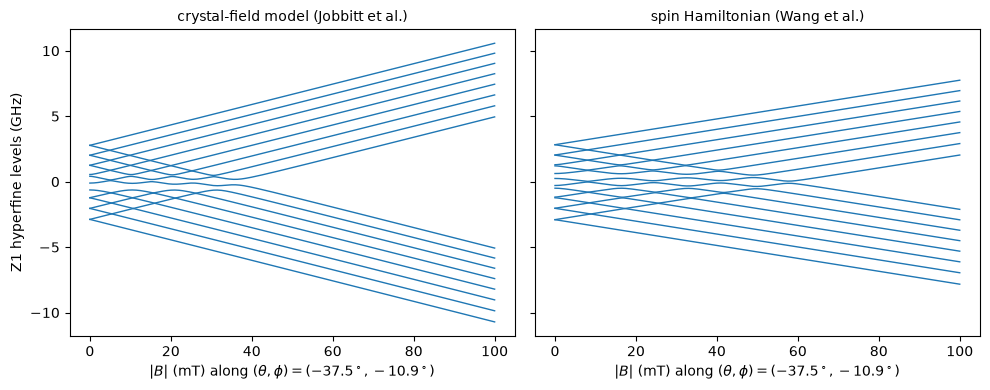

In [7]:
operators = field_operators(model)
sh0, sh_operators = spin_hamiltonian_model(ER_YSO_SITE2_WANG_SPIN_HAMILTONIAN["A"], ER_YSO_SITE2_WANG_SPIN_HAMILTONIAN["Q"], ER_YSO_SITE2_WANG_SPIN_HAMILTONIAN["g"])
z1_cf = np.linalg.eigvalsh(h0)[:16] * CM_TO_MHZ
z1_sh = np.linalg.eigvalsh(sh0)
print("zero field, Z1 hyperfine levels (MHz from the lowest):")
print("   crystal-field model:", np.round(z1_cf - z1_cf[0]).astype(int))
print("   spin Hamiltonian:   ", np.round(z1_sh - z1_sh[0]).astype(int))

fields = np.linspace(0, 0.1, 201)
direction = polar_field(1.0, -37.5383, -10.9417)  # direction of Matsuura et al.'s optimal site-2 ZEFOZ point
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (label, hz, ops, scale) in zip(axes, [("crystal-field model (Jobbitt et al.)", h0, operators, CM_TO_MHZ), ("spin Hamiltonian (Wang et al.)", sh0, sh_operators, 1.0)]):
    curves = np.array([np.linalg.eigvalsh(linear_field_hamiltonian(hz, ops, b * direction))[:16] * scale for b in fields])
    curves -= np.mean(curves[0])
    ax.plot(fields * 1e3, curves / 1e3, color="C0", lw=1)
    ax.set_title(label, fontsize=10)
    ax.set_xlabel(r"$|B|$ (mT) along $(\theta, \phi) = (-37.5^\circ, -10.9^\circ)$")
axes[0].set_ylabel("Z1 hyperfine levels (GHz)")
plt.tight_layout()
plt.savefig("pdfs_figures/Er_YSO_Z1_hyperfine_vs_field.pdf")

#### ZEFOZ points

A ZEFOZ point of the transition $i \leftrightarrow j$ is a field where the gradient $S_1 = \nabla_B \nu_{ij}$ vanishes. `zefoz_newton` finds it with Newton's method, using the exact gradient (Hellmann–Feynman) and the exact Hessian $S_2$ (second-order perturbation theory) of `transition_derivatives`, from the full 240-state Hamiltonian or from the 16-state spin Hamiltonian.

First, Matsuura et al.'s five best site-2 points (their Table V) must follow from their spin Hamiltonian. Their text prints the optimal field as $(\mp378.9, \pm73.2, \mp502.3)$ mT. That has the wrong sign of the b component with respect to their polar angles $(\theta, \phi) = (\mp37.5383^\circ, -10.9417^\circ)$; the polar form reproduces their table, the Cartesian one does not.

In [8]:
print(f"{'transition':10s} {'paper':>9s} {'spin Hamiltonian':>26s} {'crystal-field model at that field':>40s}")
for i, j, frequency, magnitude, theta, phi, t2 in ER_YSO_SITE2_MATSUURA2026_ZEFOZ:
    field = polar_field(magnitude, theta, phi)
    sh = zefoz_newton(sh0, sh_operators, field, i, j)
    nu_cf, gradient_cf, _ = transition_derivatives(h0, operators, field, i, j)
    print(f"|{i}>-|{j}>   {frequency:7.1f} MHz   {sh['frequency']:7.2f} MHz, |S1| {np.linalg.norm(sh['gradient']) * 1e-3:.0e} MHz/mT"
          f"   {nu_cf * CM_TO_MHZ:7.2f} MHz, |S1| = {np.linalg.norm(gradient_cf) * CM_TO_MHZ * 1e-3:.3f} MHz/mT")
wrong = np.array([-378.9, 73.2, -502.3]) * 1e-3
nu_wrong, gradient_wrong, _ = transition_derivatives(sh0, sh_operators, wrong, 14, 15)
print(f"\nwith the Cartesian field as printed: {nu_wrong:.2f} MHz, |S1| = {np.linalg.norm(gradient_wrong) * 1e-3:.3f} MHz/mT (not a ZEFOZ point)")

transition     paper           spin Hamiltonian        crystal-field model at that field
|14>-|15>     796.3 MHz    796.29 MHz, |S1| 3e-13 MHz/mT    756.76 MHz, |S1| = 0.015 MHz/mT
|6>-|7>     797.6 MHz    797.60 MHz, |S1| 1e-13 MHz/mT    766.96 MHz, |S1| = 0.019 MHz/mT
|13>-|14>     796.0 MHz    795.94 MHz, |S1| 6e-14 MHz/mT    773.15 MHz, |S1| = 0.018 MHz/mT
|13>-|15>    1592.2 MHz   1592.18 MHz, |S1| 2e-13 MHz/mT   1530.11 MHz, |S1| = 0.033 MHz/mT
|12>-|13>     798.0 MHz    797.96 MHz, |S1| 3e-14 MHz/mT    788.75 MHz, |S1| = 0.024 MHz/mT

with the Cartesian field as printed: 783.69 MHz, |S1| = 0.025 MHz/mT (not a ZEFOZ point)


The spin Hamiltonian reproduces Matsuura et al.'s five points (frequency to 0.1 MHz, gradient below $10^{-5}$ MHz/mT after Newton refinement from their rounded fields). The crystal-field model gives a different frequency at those fields and a non-zero gradient, so they are not ZEFOZ points of Model 3.

**Search.** As Matsuura et al. did, we search every one of the 120 transitions of Z1 from many starting fields, for both Hamiltonians and with $|\vec B| \le 3$ T. The starting fields are their $6^3$ grid of components $\pm5, \pm15, \pm25$ mT, plus the 26 directions of a cube at 0.1, 0.3, 0.6, 1 and 2 T. Points are ranked by the largest curvature $\|S_2\|$, which limits the coherence time once $S_1 = 0$ (their Eq. (5)). Newton runs are capped at 60 iterations; with 40, the search misses the second point of Matsuura et al.'s Table V. This takes about an hour on 24 processes.

In [9]:
def search_starts():
    grid = [np.array(p) * 1e-3 for p in itertools.product([-25, -15, -5, 5, 15, 25], repeat=3)]
    directions = [np.array(d, float) for d in itertools.product([-1, 0, 1], repeat=3) if any(d)]
    return grid + [b * d / np.linalg.norm(d) for d in directions for b in (0.1, 0.3, 0.6, 1.0, 2.0)]


SEARCH_MODELS = {"spin Hamiltonian": (sh0, sh_operators, 1.0), "crystal-field model": (h0, operators, CM_TO_MHZ)}


def search_transition(arguments):
    name, transition = arguments
    hz, ops, scale = SEARCH_MODELS[name]
    points = zefoz_search(hz, ops, search_starts(), [transition], max_field=3.0, max_iter=60)
    return [dict(transition=p["transition"], field=p["field"], frequency=p["frequency"] * scale, hessian=p["hessian"] * scale) for p in points]


zefoz = {}
for name in SEARCH_MODELS:
    start = time.time()
    tasks = [(name, (i, j)) for i in range(16) for j in range(i + 1, 16)]
    with ProcessPoolExecutor(max_workers=24, mp_context=mp.get_context("fork")) as pool:
        points = [p for result in pool.map(search_transition, tasks) for p in result]
    for p in points:
        p["S2"] = np.max(np.abs(np.linalg.eigvalsh(p["hessian"])))  # MHz/T^2
    zefoz[name] = sorted(points, key=lambda p: p["S2"])
    print(f"{name}: {len(points)} ZEFOZ points with |B| <= 3 T ({time.time() - start:.0f} s)")


def describe(p):
    field = p["field"]
    magnitude = np.linalg.norm(field)
    theta = np.degrees(np.arccos(field[2] / magnitude)) * (1 if field[0] >= 0 else -1)
    phi = np.degrees(np.arctan2(field[1] * np.sign(field[0] or 1), abs(field[0])))
    return (f"|{p['transition'][0]:2d}>-|{p['transition'][1]:2d}>  {p['frequency']:8.1f} MHz  |B| = {magnitude * 1e3:6.1f} mT  "
            f"(theta, phi) = ({theta:6.1f}, {phi:6.1f}) deg  ||S2|| = {p['S2'] * 1e-6:.2e} MHz/mT^2")


for name, points in zefoz.items():
    print(f"\n{name}: ten points with the smallest curvature")
    for p in points[:10]:
        print("   " + describe(p))

spin Hamiltonian: 396 ZEFOZ points with |B| <= 3 T (61 s)


crystal-field model: 258 ZEFOZ points with |B| <= 3 T (3653 s)

spin Hamiltonian: ten points with the smallest curvature
   |14>-|15>     796.3 MHz  |B| =  633.5 mT  (theta, phi) = ( -37.5,  -10.9) deg  ||S2|| = 1.65e-04 MHz/mT^2
   | 6>-| 7>     797.6 MHz  |B| =  668.5 mT  (theta, phi) = ( -38.2,  -12.6) deg  ||S2|| = 1.73e-04 MHz/mT^2
   |13>-|14>     795.9 MHz  |B| =  413.7 mT  (theta, phi) = ( -40.2,  -11.9) deg  ||S2|| = 2.83e-04 MHz/mT^2
   |13>-|15>    1592.2 MHz  |B| =  510.5 mT  (theta, phi) = ( -38.9,  -11.4) deg  ||S2|| = 4.32e-04 MHz/mT^2
   |12>-|13>     798.0 MHz  |B| =  283.9 mT  (theta, phi) = ( -42.2,  -12.6) deg  ||S2|| = 5.04e-04 MHz/mT^2
   | 5>-| 7>    1594.6 MHz  |B| =  513.3 mT  (theta, phi) = ( -39.3,  -12.8) deg  ||S2|| = 5.21e-04 MHz/mT^2
   | 5>-| 6>     797.0 MHz  |B| =  335.7 mT  (theta, phi) = ( -40.8,  -13.1) deg  ||S2|| = 5.49e-04 MHz/mT^2
   |12>-|14>    1593.9 MHz  |B| =  344.1 mT  (theta, phi) = ( -41.3,  -12.2) deg  ||S2|| = 7.44e-04 MHz/mT^2
   |12>

**Result.** On the spin Hamiltonian the search returns exactly the five transitions of Matsuura et al.'s Table V, in the same order and at their fields, which validates the search. The crystal-field model gives a different landscape: its best ZEFOZ points lie at 90–150 mT near the D1–D2 plane ($\theta \approx -80^\circ$), against 280–670 mT at $\theta \approx -40^\circ$ for the measured spin Hamiltonian. The site-2 parameters reproduce the 7 T splittings they were tested on but are not accurate enough to predict ZEFOZ points.

The search on the spin Hamiltonian is a check of the search itself: it should return Matsuura et al.'s Table V. For each of their five transitions, the next cell gives the nearest ZEFOZ point of the crystal-field model.

In [10]:
print(f"{'transition':10s} {'Matsuura et al. |B|':>20s} {'nearest crystal-field ZEFOZ point of the same transition':>60s}")
for i, j, frequency, magnitude, theta, phi, t2 in ER_YSO_SITE2_MATSUURA2026_ZEFOZ:
    reference = polar_field(magnitude, theta, phi)
    same = [p for p in zefoz["crystal-field model"] if p["transition"] == (i, j)]
    nearest = min(same, key=lambda p: np.linalg.norm(p["field"] - reference)) if same else None
    text = "none" if nearest is None else f"{nearest['frequency']:7.1f} MHz, {np.linalg.norm(nearest['field'] - reference) * 1e3:6.0f} mT away, |B| = {np.linalg.norm(nearest['field']) * 1e3:6.1f} mT, ||S2|| = {nearest['S2'] * 1e-6:.1e} MHz/mT^2"
    print(f"|{i}>-|{j}>     {magnitude * 1e3:8.0f} mT, {frequency:7.1f} MHz   {text}")
for name, points in zefoz.items():
    curvature = np.array([p["S2"] for p in points]) * 1e-6
    print(f"{name}: smallest ||S2|| {curvature.min():.1e} MHz/mT^2, median {np.median(curvature):.1e} MHz/mT^2")

transition  Matsuura et al. |B|     nearest crystal-field ZEFOZ point of the same transition
|14>-|15>          633 mT,   796.3 MHz     762.1 MHz,    556 mT away, |B| =  106.1 mT, ||S2|| = 5.6e-04 MHz/mT^2
|6>-|7>          668 mT,   797.6 MHz     766.8 MHz,    571 mT away, |B| =  149.9 mT, ||S2|| = 5.3e-04 MHz/mT^2
|13>-|14>          413 mT,   796.0 MHz     776.7 MHz,    339 mT away, |B| =  100.1 mT, ||S2|| = 6.9e-04 MHz/mT^2
|13>-|15>          510 mT,  1592.2 MHz    1538.8 MHz,    435 mT away, |B| =  102.9 mT, ||S2|| = 1.2e-03 MHz/mT^2
|12>-|13>          283 mT,   798.0 MHz     791.3 MHz,    215 mT away, |B| =   92.9 mT, ||S2|| = 9.0e-04 MHz/mT^2
spin Hamiltonian: smallest ||S2|| 1.7e-04 MHz/mT^2, median 1.5e+02 MHz/mT^2
crystal-field model: smallest ||S2|| 5.3e-04 MHz/mT^2, median 2.2e+01 MHz/mT^2


#### The field sweep for DBQA

DBQA in `Example_9` is benchmarked on the crystal-field model itself; the exact spectrum of $H(\vec B)$ is the reference. We take the ZEFOZ point of the crystal-field model with the smallest curvature among those with $0.1 \le |\vec B| \le 1$ T. In that range the hyperfine states of Z1 are not mixed by the zero-field terms and Z1 stays well separated from Z2. The rule was fixed before the search. The field is swept along the direction of that point, $\vec B = b\,\hat n$, over 21 values of $b$ in $[0.8, 1.2]\,|\vec B^*|$.

In [11]:
candidates = [p for p in zefoz["crystal-field model"] if 0.1 <= np.linalg.norm(p["field"]) <= 1.0]
chosen = candidates[0]
b_star = np.linalg.norm(chosen["field"])
direction_star = chosen["field"] / b_star
magnitudes = b_star * np.linspace(0.8, 1.2, 21)
i, j = chosen["transition"]
print("chosen: " + describe(chosen))
print(f"curvature along the sweep direction: {direction_star @ chosen['hessian'] @ direction_star * 1e-6:.2e} MHz/mT^2")
nu_line, gaps_line = [], []
for b in magnitudes:
    e = np.linalg.eigvalsh(linear_field_hamiltonian(h0, operators, b * direction_star))
    nu_line.append((e[j] - e[i]) * CM_TO_MHZ)
    gaps_line.append(np.min(np.diff(e[:16])) * CM_TO_MHZ)
print(f"over the sweep: nu varies by {np.ptp(nu_line):.4f} MHz; smallest gap inside Z1 {np.min(gaps_line):.1f} MHz")
sweep = dict(transition=chosen["transition"], field=chosen["field"], frequency=chosen["frequency"], hessian=chosen["hessian"],
             direction=direction_star, magnitudes=magnitudes)
with open("simulation_results/Er_YSO_validation.pickle", "wb") as file:
    pickle.dump(dict(strengths=strengths, level_residuals=residual, g_pycf=g_pycf, zefoz=zefoz, sweep=sweep), file)

chosen: | 6>-| 7>     766.8 MHz  |B| =  149.9 mT  (theta, phi) = ( -82.0,   -3.2) deg  ||S2|| = 5.32e-04 MHz/mT^2
curvature along the sweep direction: 1.40e-04 MHz/mT^2
over the sweep: nu varies by 0.0827 MHz; smallest gap inside Z1 761.7 MHz


**Summary of the validation.**
- Transcription: the crystal-field strengths of Table III are reproduced exactly.
- Full $4f^{11}$ basis: crystal-field splittings inside each multiplet to 0.6 cm$^{-1}$ rms and g values to 0.07 rms; the multiplets are rigidly shifted by up to 37 cm$^{-1}$, a convention difference of the bundled `f11cf` basis that no refit explains (both sites).
- Hyperfine basis (Model 3): Table VI reproduced to 0.7 MHz (without nuclear Zeeman, as in the paper).
- ZEFOZ: Matsuura et al.'s points follow from their spin Hamiltonian (polar form of their field); the crystal-field model has its own ZEFOZ points, and the best one in 0.1–1 T, $|6\rangle$–$|7\rangle$ at 149.9 mT, defines the field sweep of `Example_9`.